<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-04/lab-011-cnn-tc.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning for Scientific Discovery
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 011 <br>
**Reading:** Lecture Notes, Chapter 2 (*Fundamentals of Deep Learning*), Section *Deep Learning in the Classical 2D Ising Model*; Section *Understanding Deep Learning through the Chinese Room Thought Experiment*
<hr/>

# Lab 011 — Critical temperature from network confidence

This notebook reproduces the experiment of Lecture 4 (Lecture Notes, Chapter 2), in which a convolutional neural network (CNN) finds the critical temperature $T_c$ of the two-dimensional (2D) Ising model without ever being told where it is.

We start from Monte Carlo spin configurations of an $L\times L$ Ising model on a grid of temperatures, either from Lab 010 or generated here. Only the configurations far from the transition receive labels: those with $T<1.5$ are called *ordered* ($y=0$) and those with $T>3.0$ *disordered* ($y=1$). Everything in between is never shown to the network during training. A small CNN then learns to tell the two classes apart, which is an easy task. The interesting question comes afterwards: we ask the trained network about **all** temperatures and look for the temperature where it is least confident. That temperature, $\bar T_c$, is our estimate of $T_c$.

Because a finite lattice has no sharp transition, we repeat the experiment for several lattice sizes to see the **finite-size effects**. Finally we try to open the Chinese room of Lecture 4 and ask what the network has actually learned.

The exact answer, for comparison, is (Onsager 1944, with $J$ and $k_B$ set to 1)
$$T_c = \frac{2}{\ln(1+\sqrt2)} \approx 2.2692. \tag{1}$$

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook* (or open it from Google Drive).
> 2. Run cells one by one with **Shift + Enter**. Run them *in order* — later cells use variables defined earlier.
> 3. The required packages (`numpy`, `scipy`, `matplotlib`, `torch`) are pre-installed in Colab; no `pip install` required.
> 4. The notebook looks for the dataset `data/ising_Nx{L}_Ny{L}.npz` made by Lab 010. If it is not there, it generates it (this takes from seconds to about a minute, depending on $L$).
>    In Colab you can upload the file from Lab 010 into a folder `data/`, or let the notebook generate it.
> 5. If the notebook state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy.stats import spearmanr
import torch
import torch.nn as nn

torch.manual_seed(0)                    # fixes the random initial parameters
rng = np.random.default_rng(0)          # NumPy random generator (data generation, train/validation split)

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
cmap_T = LinearSegmentedColormap.from_list("T", [UJNavy, "#D9DCE1", DSOrange])   # below T_c -> above T_c
cmap_w = LinearSegmentedColormap.from_list("w", [UJNavy, "white", DSOrange])     # for weights (sign)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

TC = 2.0 / np.log(1.0 + np.sqrt(2.0))
print("PyTorch", torch.__version__, "  NumPy", np.__version__, f"   exact T_c = {TC:.6f}")

PyTorch 2.9.0+cpu   NumPy 2.1.3    exact T_c = 2.269185


<hr/>
## 1. The data

One sample is a spin configuration $\boldsymbol s\in\{-1,+1\}^{L\times L}$ of the 2D Ising model with periodic boundaries; each entry is the orientation of one spin. The configurations are drawn from the Boltzmann distribution
$$p(\boldsymbol s)\propto e^{-H(\boldsymbol s)/T},\qquad H(\boldsymbol s)=-\sum_{\langle ij\rangle}s_is_j, \tag{2}$$
by the checkerboard Metropolis algorithm (N. Metropolis, A. W. Rosenbluth, M. N. Rosenbluth, A. H. Teller and E. Teller, *J. Chem. Phys.* **21**, 1087 (1953), [doi:10.1063/1.1699114](https://doi.org/10.1063/1.1699114)) of Lab 010, where the sampler is derived and tested. A compact copy of it generates the data when the file of Lab 010 is missing, in the same format: `configs` with shape `(temperatures, samples, L, L)` and the temperature grid `T`. For each of the 51 temperatures $T=1.00, 1.05,\dots,3.50$ there are 200 configurations, each multiplied by a random global sign, since $H$ is symmetric under $\boldsymbol s\to-\boldsymbol s$. The data carry no labels of their own: the labels "ordered" and "disordered" are assigned from the temperature in Section 2.

In [2]:
def metropolis_sweep(s, beta, masks, rng):
    # One checkerboard Metropolis sweep (in place) of a batch of lattices s: (..., Ny, Nx), periodic boundaries.
    for mask in masks:
        nn_sum = (np.roll(s, 1, -1) + np.roll(s, -1, -1) + np.roll(s, 1, -2) + np.roll(s, -1, -2))
        accept = rng.random(s.shape, dtype=np.float32) < np.exp(-beta * 2.0 * s * nn_sum)
        s[...] = np.where(mask & accept, -s, s)

def generate_dataset(Nx, Ny, temperatures, n_chains, n_samples, n_equil, n_between, rng):
    # Cold start, burn-in, then n_samples stored configurations per chain; random global spin flip at the end.
    y, x = np.indices((Ny, Nx)); black = (x + y) % 2 == 0
    beta = (1.0 / temperatures.astype(np.float32))[None, :, None, None]
    s = np.ones((n_chains, len(temperatures), Ny, Nx), np.float32)
    for _ in range(n_equil):
        metropolis_sweep(s, beta, (black, ~black), rng)
    stored = np.empty((n_samples, n_chains, len(temperatures), Ny, Nx), np.int8)
    for k in range(n_samples):
        for _ in range(n_between):
            metropolis_sweep(s, beta, (black, ~black), rng)
        stored[k] = s
    configs = stored.transpose(2, 0, 1, 3, 4).reshape(len(temperatures), n_samples * n_chains, Ny, Nx)
    flip = rng.choice(np.array([-1, 1], np.int8), size=configs.shape[:2])
    return configs * flip[:, :, None, None]

def load_or_generate(L, rng, samples_per_T=200):
    path = f"data/ising_Nx{L}_Ny{L}.npz"
    if os.path.exists(path):
        d = np.load(path)
        print(f"loaded {path}: configs {d['configs'].shape}")
        return d["configs"], d["T"]
    temperatures = np.round(np.arange(1.0, 3.5 + 1e-9, 0.05), 2)
    n_chains = 20 if L <= 20 else 10                       # fewer, longer chains for large lattices (same 200 samples per T)
    t0 = time.time()
    configs = generate_dataset(L, L, temperatures, n_chains=n_chains, n_samples=samples_per_T // n_chains,
                               n_equil=1000 + 2 * L * L // 4, n_between=20, rng=rng)
    os.makedirs("data", exist_ok=True)
    np.savez_compressed(path, configs=configs, T=temperatures, Nx=L, Ny=L)
    print(f"generated {path}: configs {configs.shape} in {time.time() - t0:.1f} s")
    return configs, temperatures

L = 20
configs, temperatures = load_or_generate(L, rng)

loaded data/ising_Nx20_Ny20.npz: configs (51, 200, 20, 20)


Two configurations at each of five temperatures, for $L=20$ (orange $s=+1$, navy $s=-1$). Far below $T_c$ one orientation fills the lattice up to small islands; close to $T_c$ clusters of all sizes coexist; far above $T_c$ neighbouring spins are almost uncorrelated and $|m|$ is small.

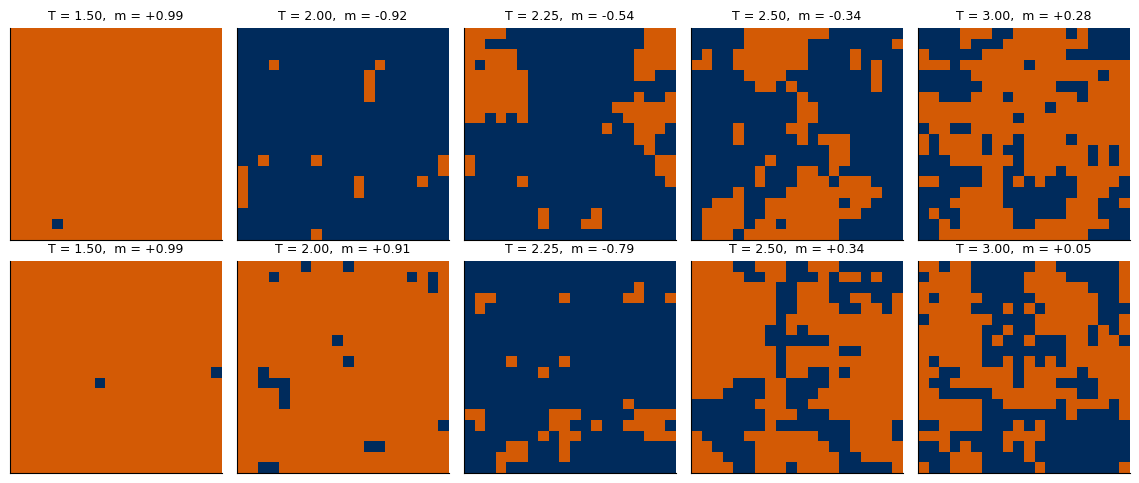

In [3]:
show_T = [1.5, 2.0, 2.25, 2.5, 3.0]
fig, axes = plt.subplots(2, len(show_T), figsize=(2.3 * len(show_T), 4.9))
for col, T in enumerate(show_T):
    k = int(np.argmin(np.abs(temperatures - T)))
    for row in range(2):
        s = configs[k, row]
        axes[row, col].imshow(s, cmap=cmap_w, vmin=-1, vmax=1)
        axes[row, col].set_title(f"T = {temperatures[k]:.2f},  m = {s.mean():+.2f}", fontsize=9)
        axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
plt.tight_layout(); plt.show()


<hr/>
## 2. Labels, loss and confidence

Each configuration gets a label from its temperature:
$$
y = \begin{cases} 0 \ (\text{ordered}) & T < T_{\min}=1.5\\ 1 \ (\text{disordered}) & T>T_{\max}=3.0 \\ \text{not used for training} & T_{\min}\le T\le T_{\max}\end{cases} \tag{3}$$
The network outputs two numbers (logits) $z_0, z_1$, turned into probabilities by the **softmax**
$$
p_k(\boldsymbol s) = \frac{e^{z_k}}{e^{z_0}+e^{z_1}}, \qquad p_0+p_1 = 1, \tag{4}$$
and is trained by minimising the **categorical cross-entropy** (Lecture 4)
$$\mathcal L = -\frac1n\sum_{a}\ln p_{y_a}(\boldsymbol s_a). \tag{5}$$

For any configuration the prediction is the class with the larger probability, and we call that probability the **confidence**:
$$
\mathrm{conf}(\boldsymbol s) = \max\left(p_0(\boldsymbol s),\,p_1(\boldsymbol s)\right)\in\left[\tfrac12, 1\right]. \tag{6}$$
The network is confident on configurations that look like its training data. Close to $T_c$ the configurations are neither clearly ordered nor clearly disordered, so we expect the confidence to approach $\frac12$ there. This motivates the estimate
$$
\bar T_c = \arg\min_T \ \big\langle \mathrm{conf}\big\rangle_T , \tag{7}$$
the temperature of lowest average confidence. A closely related estimate is the temperature where the average $\langle p_1\rangle_T$ crosses $\frac12$.

In [4]:
T_MIN, T_MAX = 1.5, 3.0

def make_training_set(configs, temperatures, rng, val_fraction=0.2):
    low, high = temperatures < T_MIN, temperatures > T_MAX
    X = np.concatenate([configs[low].reshape(-1, *configs.shape[2:]), configs[high].reshape(-1, *configs.shape[2:])])
    y = np.concatenate([np.zeros(configs[low].shape[0] * configs.shape[1]), np.ones(configs[high].shape[0] * configs.shape[1])])
    perm = rng.permutation(len(y))
    X, y = X[perm], y[perm]
    n_val = int(val_fraction * len(y))
    to_t = lambda a: torch.tensor(a, dtype=torch.float32).unsqueeze(1)   # (n, 1, L, L): one input channel
    return (to_t(X[n_val:]), torch.tensor(y[n_val:], dtype=torch.long),
            to_t(X[:n_val]), torch.tensor(y[:n_val], dtype=torch.long))

X_tr, y_tr, X_val, y_val = make_training_set(configs, temperatures, rng)
print(f"training: {len(y_tr)} configurations, validation: {len(y_val)};  fraction of label 1 in training = {y_tr.float().mean():.3f}")
print(f"temperatures used for label 0: {temperatures[temperatures < T_MIN]}")
print(f"temperatures used for label 1: {temperatures[temperatures > T_MAX]}")

training: 3200 configurations, validation: 800;  fraction of label 1 in training = 0.496
temperatures used for label 0: [1.   1.05 1.1  1.15 1.2  1.25 1.3  1.35 1.4  1.45]
temperatures used for label 1: [3.05 3.1  3.15 3.2  3.25 3.3  3.35 3.4  3.45 3.5 ]


<hr/>
## 3. The network

As in the Lecture Notes, the network has two convolutional layers with $32$ kernels of size $3\times3$, each followed by a rectified linear unit (ReLU) and $2\times2$ max-pooling, then a dense layer of $64$ ReLU nodes and an output layer of $2$ nodes (the softmax is part of the loss).

One detail is motivated by the physics: we use **circular padding** (`padding_mode="circular"`). Our lattice is a torus, so the neighbour of the last column is the first column; circular padding makes the convolution see exactly the same neighbourhoods as the Hamiltonian.

In [5]:
class IsingCNN(nn.Module):
    def __init__(self, L, channels=32, hidden=64):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, channels, 3, padding=1, padding_mode="circular"), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(channels, channels, 3, padding=1, padding_mode="circular"), nn.ReLU(), nn.MaxPool2d(2))
        side = L // 4                                          # two 2x2 poolings
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(channels * side * side, hidden), nn.ReLU(),
                                        nn.Linear(hidden, 2))
    def forward(self, x):
        return self.classifier(self.features(x))               # logits z_0, z_1

model = IsingCNN(L)
W0 = model.features[0].weight.detach().clone()                 # first-layer filters before training (used in Section 7.3)
print(model)
print("number of parameters:", sum(p.numel() for p in model.parameters()))

IsingCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), padding_mode=circular)
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), padding_mode=circular)
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=800, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=2, bias=True)
  )
)
number of parameters: 60962


### Architecture diagrams

The printout lists the layers but not the flow of numbers through them. We show the architecture in two ways: with a drawing function of our own and with two libraries that read it directly from the PyTorch model.

The function `draw_network` draws a fully connected network as it is usually sketched on a blackboard. Each layer is a column of circles, one per neuron, and thin grey lines join every neuron to every neuron of the next layer, since a dense layer connects all of them. A layer with more than `max_nodes` neurons is shown by its first and last few neurons with a vertical ellipsis in between, and its true size is written under the column. The height of a column grows with the logarithm of the layer size, so a wide layer is visibly taller than a narrow one. Input and output layers are grey and hidden layers blue; orange is reserved for a latent layer and green for an additional input such as a class label.

For a network of your own, pass the layer sizes from the input to the output, e.g. `draw_network([784, 128, 10])`; `labels`, `colors` and `groups` (brackets over ranges of columns) are optional, and `ax=` draws into a panel of an existing figure. An entry of the list may itself be a list of sizes: the column then holds several blocks, which is how two inputs entering the same layer are drawn. Only dense layers can be drawn this way. A convolutional layer is a set of small kernels shared by all positions of the image, not a column of independent neurons, so the convolutional part of a network is left to the library tools further below.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# Colours used for the network drawings: grey for the data (input and output),
# blue for hidden layers, orange for the latent (bottleneck) layer and green
# for an extra conditioning input such as a one-hot class label.
GREY, BLUE, ORANGE, GREEN = "#8C8C8C", "#005CA7", "#EB6709", "#2E8B57"


def draw_network(layer_sizes, labels=None, colors=None, max_nodes=10,
                 groups=None, no_input=None, ax=None, node_radius=0.11,
                 x_gap=1.6, min_height=1.0, height_scale=1.1, fontsize=13):
    """Draw a fully connected network as columns of circles joined by edges.

    Parameters
    ----------
    layer_sizes : list
        One entry per column, from the input to the output. An entry is
        either an int (the number of neurons of one layer) or a list of ints
        (several blocks stacked in the same column, e.g. [16, 16] for the mean
        and the log-variance of a variational autoencoder, or [784, 10] for an
        image together with a one-hot condition).
    labels : list, optional
        Names shown under each column next to the true layer size. An entry
        may be None (size only), a string, or, for a stacked column, a list
        with one string per block.
    colors : list, optional
        Fill colour of the nodes of each column (or a list with one colour per
        block). By default the first and the last column are grey and all
        others blue.
    max_nodes : int
        Largest number of circles drawn for one block. A larger block is shown
        by its first and last few nodes with a vertical ellipsis in between;
        the true size is always shown in the label.
    groups : list of (text, first_column, last_column), optional
        Brackets drawn above a range of columns, e.g. ("encoder", 0, 2).
    no_input : list of (column, block), optional
        Blocks that receive no edges from the previous column, e.g. a condition
        c that enters the decoder from outside.
    ax : matplotlib Axes, optional
        Axes to draw into; a new figure is created when None.
    node_radius, x_gap : float
        Radius of a circle and horizontal distance between columns.
    min_height, height_scale : float
        The height of a block of size s is min_height + height_scale*log10(s),
        so that a narrow layer is visibly shorter than a wide one.
    fontsize : int
        Font size of all labels.

    Returns
    -------
    ax : the matplotlib Axes with the drawing.
    """
    n = len(layer_sizes)
    # Turn every entry into a list of blocks, so that a plain layer is a
    # column with a single block.
    blocks = [s if isinstance(s, (list, tuple)) else [s] for s in layer_sizes]
    if labels is None:
        labels = [None] * n
    if colors is None:
        colors = [GREY] + [BLUE] * (n - 2) + [GREY]
    no_input = set(no_input or [])

    def per_block(value, k):
        # Repeat a single value for all k blocks of a column, or keep a list.
        return list(value) if isinstance(value, (list, tuple)) else [value] * k

    if ax is None:
        _, ax = plt.subplots(figsize=(1.9 * n + 1, 5.5))

    # ---- Node positions ---------------------------------------------------
    # Column i sits at x = i * x_gap. Inside a column the blocks are stacked
    # from top to bottom with a small gap, and the whole column is centred
    # on y = 0. Each block gets a height that grows with log10 of its size
    # (but is never too small for its circles to fit without overlapping);
    # the drawn nodes are spread evenly over that height.
    nodes = []            # nodes[i][b] = list of (x, y) of block b in column i
    tops, bottoms = [], []
    gap = 0.9             # vertical space between stacked blocks (holds a label)
    for i, blk in enumerate(blocks):
        cols = per_block(colors[i], len(blk))
        labs = per_block(labels[i], len(blk))
        heights = [max(min_height + height_scale * np.log10(s),
                       (min(s, max_nodes) - 1) * 2.3 * node_radius) for s in blk]
        total = sum(heights) + gap * (len(blk) - 1)
        x, y_top = i * x_gap, total / 2
        column = []
        for s, h, c, lab in zip(blk, heights, cols, labs):
            shown = min(s, max_nodes)
            if s <= max_nodes:
                # Small block: draw every neuron.
                ys = np.linspace(y_top, y_top - h, shown) if shown > 1 else np.array([y_top - h / 2])
            else:
                # ---- Truncation of large layers ----------------------------
                # Draw max_nodes circles: half in the upper 38 % of the block,
                # half in the lower 38 %, and a vertical ellipsis in the
                # middle to show that neurons are omitted.
                k = max_nodes // 2
                ys = np.concatenate([np.linspace(y_top, y_top - 0.38 * h, k),
                                     np.linspace(y_top - 0.62 * h, y_top - h, max_nodes - k)])
                ax.text(x, y_top - 0.5 * h, r"$\vdots$", ha="center", va="center",
                        fontsize=fontsize + 6, color=c, zorder=4)
            for y in ys:
                ax.add_patch(Circle((x, y), node_radius, facecolor=c,
                                    edgecolor="black", lw=0.6, zorder=3))
            column.append([(x, y) for y in ys])

            # ---- Labels of stacked blocks ----------------------------------
            # In a column with several blocks each block is labelled just
            # below its last node, in its own colour, on a white box so that
            # the edges behind do not hide the text.
            if len(blk) > 1:
                text = f"{s}" if lab is None else f"{lab} {s}"
                ax.text(x, y_top - h - 0.2, text, ha="center", va="top",
                        fontsize=fontsize - 1, color=c, zorder=5,
                        bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
            y_top -= h + gap

        # ---- Label of a single-block column: name and true size below ----
        if len(blk) == 1:
            lab = labs[0]
            text = f"{blk[0]}" if lab is None else f"{lab}\n{blk[0]}"
            ax.text(x, -total / 2 - 0.3, text, ha="center", va="top", fontsize=fontsize)
        nodes.append(column)
        tops.append(total / 2)
        bottoms.append(-total / 2)

    # ---- Edges ---------------------------------------------------------------
    # A dense layer connects every neuron of one column with every neuron of
    # the next, so we draw a thin grey line for every pair of drawn nodes,
    # skipping the blocks listed in no_input. zorder=1 keeps lines behind
    # the circles.
    for i in range(n - 1):
        sources = [p for block in nodes[i] for p in block]
        for b, block in enumerate(nodes[i + 1]):
            if (i + 1, b) in no_input:
                continue
            for (x0, y0) in sources:
                for (x1, y1) in block:
                    ax.plot([x0, x1], [y0, y1], color="#B0B0B0", lw=0.35, zorder=1)

    # ---- Group brackets ------------------------------------------------------
    # A bracket above columns first..last with its text, e.g. "encoder".
    y_br = max(tops) + 0.45
    for text, i0, i1 in (groups or []):
        x0, x1 = i0 * x_gap - 0.3, i1 * x_gap + 0.3
        ax.plot([x0, x0, x1, x1], [y_br - 0.12, y_br, y_br, y_br - 0.12],
                color="black", lw=1.2)
        ax.text((x0 + x1) / 2, y_br + 0.1, text, ha="center", va="bottom",
                fontsize=fontsize)

    # ---- Axes limits ----------------------------------------------------------
    # Leave room for the brackets above and the labels below.
    ax.set_xlim(-0.8, (n - 1) * x_gap + 0.8)
    ax.set_ylim(min(bottoms) - 1.3, y_br + (0.7 if groups else 0.2))
    ax.set_aspect("equal")
    ax.axis("off")
    return ax


The convolutional part turns an $L\times L$ configuration into $32$ feature maps of size $(L/4)\times(L/4)$; for $L=20$ these are
$$32\cdot5\cdot5=800 \tag{8}$$
numbers. From there on the network is an ordinary dense network, $800\to64\to2$. The edges between its first two columns carry
$$800\cdot64+64=51\,264 \tag{9}$$
of the $60\,962$ parameters: the bulk of the model is the first dense layer, not the convolutions.

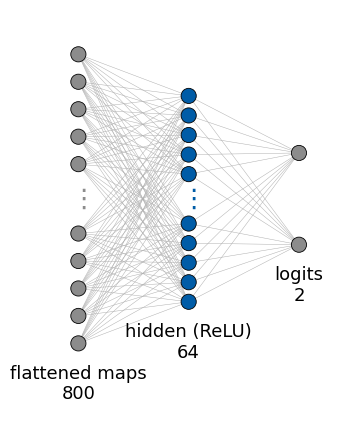

In [7]:
dense_in = model.classifier[1].in_features                     # 32 * (L/4)^2 = 800 for L = 20
draw_network([dense_in, model.classifier[1].out_features, model.classifier[3].out_features],
             labels=["flattened maps", "hidden (ReLU)", "logits"])
plt.show()


The library way to inspect a PyTorch model is `torchinfo.summary`. It sends one input through the model and prints one row per layer, with the shape of the layer's output and its number of parameters, followed by the totals, split into trainable and non-trainable parameters. The input is given by its shape, `input_size=(1, 1, L, L)`, or as a tensor, `input_data=...`. We pass a tensor of zeros: with `input_size` the library draws a random input, which would advance PyTorch's random number generator and change the training runs that follow. `col_names` selects the columns and `depth` the level of nested modules that is expanded; the model itself, including its training or evaluation mode, is left unchanged. Both libraries are installed with `pip install torchinfo torchview`; the first lines of the code install them when they are missing. The output shapes trace the lattice through the two poolings, $20\times20\to10\times10\to5\times5$, and the total must equal the $60\,962$ counted above.

In [8]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("torchinfo") is None or importlib.util.find_spec("torchview") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torchinfo", "torchview", "graphviz"])   # e.g. in Google Colab
from torchinfo import summary
from torchview import draw_graph
import IPython.display as ipd

print(summary(model, input_data=torch.zeros(1, 1, L, L), col_names=("output_size", "num_params"), verbose=0))


Layer (type:depth-idx)                   Output Shape              Param #
IsingCNN                                 [1, 2]                    --
├─Sequential: 1-1                        [1, 32, 5, 5]             --
│    └─Conv2d: 2-1                       [1, 32, 20, 20]           320
│    └─ReLU: 2-2                         [1, 32, 20, 20]           --
│    └─MaxPool2d: 2-3                    [1, 32, 10, 10]           --
│    └─Conv2d: 2-4                       [1, 32, 10, 10]           9,248
│    └─ReLU: 2-5                         [1, 32, 10, 10]           --
│    └─MaxPool2d: 2-6                    [1, 32, 5, 5]             --
├─Sequential: 1-2                        [1, 2]                    --
│    └─Flatten: 2-7                      [1, 800]                  --
│    └─Linear: 2-8                       [1, 64]                   51,264
│    └─ReLU: 2-9                         [1, 64]                   --
│    └─Linear: 2-10                      [1, 2]                    130
Total 

`torchview.draw_graph` traces the same forward pass and draws it as a graph: every layer is a box with the shapes of its input and output tensors, and the arrows follow the data. With `expand_nested=True` each submodule (an `nn.Sequential` inside the model, for example) becomes a frame around its own layers. The result is a Graphviz object; `graph.visual_graph.render` writes it to a PNG file, which needs the Graphviz program `dot` (preinstalled in Google Colab). The table is the tool for checking shapes and counting parameters, for instance after a layer has been resized; the graph shows the flow of data, which matters once a model has nested blocks, branches or skip connections.

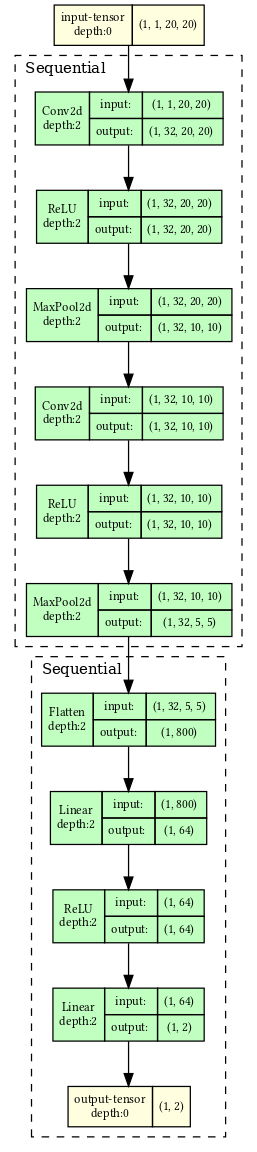

In [9]:
os.makedirs("figures", exist_ok=True)
graph = draw_graph(model, input_data=torch.zeros(1, 1, L, L), expand_nested=True)
graph.visual_graph.render("figures/Lab_011_IsingCNN_graph", format="png", cleanup=True)
ipd.display(ipd.Image(filename="figures/Lab_011_IsingCNN_graph.png"))


<hr/>
## 4. Training

The network is trained with the Adam optimiser on mini-batches of 64 configurations for 5 epochs. After each epoch the loss and accuracy are printed for the training set and for the validation set, the 20% of labelled configurations held back from training.

In [10]:
def train(model, X_tr, y_tr, X_val, y_val, epochs=5, batch_size=64, lr=1e-3, verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()                            # softmax + categorical cross-entropy
    history = []
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(y_tr))
        for i in range(0, len(y_tr), batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = loss_fn(model(X_tr[idx]), y_tr[idx])
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            out_tr, out_val = model(X_tr), model(X_val)
            rec = (loss_fn(out_tr, y_tr).item(), (out_tr.argmax(1) == y_tr).float().mean().item(),
                   loss_fn(out_val, y_val).item(), (out_val.argmax(1) == y_val).float().mean().item())
        history.append(rec)
        if verbose:
            print(f"epoch {epoch + 1:2d}: train loss {rec[0]:.2e} acc {rec[1]:.4f} | validation loss {rec[2]:.2e} acc {rec[3]:.4f}")
    return np.array(history)

t0 = time.time()
history = train(model, X_tr, y_tr, X_val, y_val)
print(f"training time: {time.time() - t0:.1f} s")

epoch  1: train loss 5.89e-06 acc 1.0000 | validation loss 5.81e-06 acc 1.0000


epoch  2: train loss 3.47e-06 acc 1.0000 | validation loss 3.39e-06 acc 1.0000


epoch  3: train loss 2.88e-06 acc 1.0000 | validation loss 2.86e-06 acc 1.0000


epoch  4: train loss 2.51e-06 acc 1.0000 | validation loss 2.52e-06 acc 1.0000


epoch  5: train loss 2.23e-06 acc 1.0000 | validation loss 2.26e-06 acc 1.0000
training time: 34.8 s


The two classes are easy to separate (at $T<1.5$ almost all spins are aligned, at $T>3$ they are not), so the training and validation accuracies reach $1$ already after the first epoch. The informative part is what the network says about temperatures it has **never seen**.
<hr/>
## 5. Predictions at all temperatures

Every configuration at every temperature is passed through the trained network; the averages of $p_1$ and of the confidence over the samples at each temperature give both estimates of $T_c$.

In [11]:
def predict(model, configs):
    # Softmax probabilities p_1 (disordered) for all configurations: array (temperatures, samples).
    model.eval()
    X = torch.tensor(configs.reshape(-1, 1, *configs.shape[2:]), dtype=torch.float32)
    with torch.no_grad():
        p = torch.cat([torch.softmax(model(X[i:i + 2048]), dim=1)[:, 1] for i in range(0, len(X), 2048)])
    return p.numpy().reshape(configs.shape[:2])

def estimate_Tc(temperatures, p1):
    conf = np.maximum(p1, 1 - p1)
    conf_mean, p1_mean = conf.mean(1), p1.mean(1)
    T_conf = temperatures[np.argmin(conf_mean)]                       # lowest average confidence
    i = np.argmax(p1_mean >= 0.5)                                     # first temperature where <p_1> >= 1/2
    T_cross = temperatures[i - 1] + (0.5 - p1_mean[i - 1]) * (temperatures[i] - temperatures[i - 1]) / (p1_mean[i] - p1_mean[i - 1])
    return conf_mean, p1_mean, T_conf, T_cross

p1 = predict(model, configs)
conf_mean, p1_mean, T_conf, T_cross = estimate_Tc(temperatures, p1)
print(f"L = {L}:  T_c from minimum of confidence = {T_conf:.2f}   |  T_c from <p_1> = 1/2 crossing = {T_cross:.3f}   |  exact T_c = {TC:.4f}")

L = 20:  T_c from minimum of confidence = 2.20   |  T_c from <p_1> = 1/2 crossing = 2.247   |  exact T_c = 2.2692


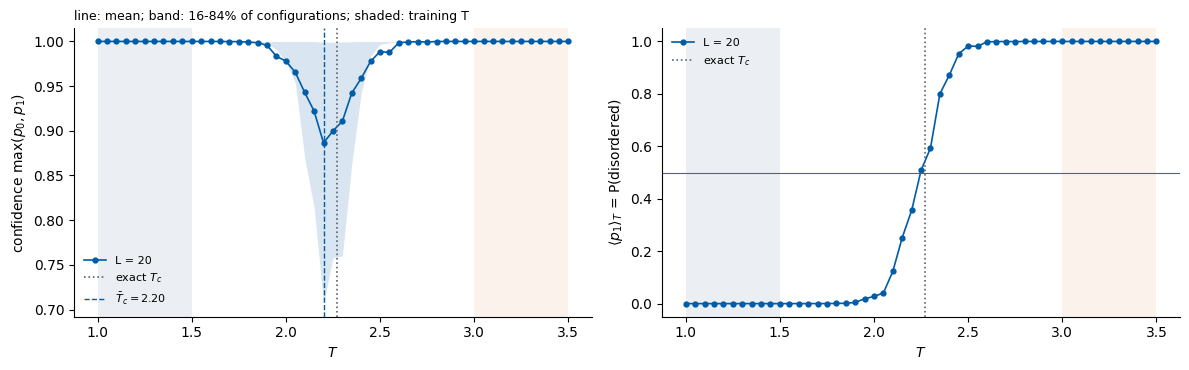

In [12]:
def plot_confidence(ax_conf, ax_p, temperatures, p1, label, colour, marker="o", band=True):
    conf = np.maximum(p1, 1 - p1)
    ax_conf.plot(temperatures, conf.mean(1), marker + "-", ms=3.5, lw=1.2, color=colour, label=label)
    if band:                                                   # spread over configurations: 16th to 84th percentile
        ax_conf.fill_between(temperatures, *np.percentile(conf, [16, 84], axis=1), color=colour, alpha=0.15, lw=0)
    ax_p.plot(temperatures, p1.mean(1), marker + "-", ms=3.5, lw=1.2, color=colour, label=label)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
plot_confidence(ax1, ax2, temperatures, p1, f"L = {L}", UJBlue)
for ax in (ax1, ax2):
    ax.axvspan(temperatures.min(), T_MIN, color=UJNavy, alpha=0.08, lw=0)
    ax.axvspan(T_MAX, temperatures.max(), color=DSOrange, alpha=0.08, lw=0)
    ax.axvline(TC, color=UJGray, ls=":", lw=1.2, label=r"exact $T_c$")
    ax.set_xlabel("$T$")
ax1.axvline(T_conf, color=UJBlue, ls="--", lw=1, label=rf"$\bar T_c = {T_conf:.2f}$")
ax2.axhline(0.5, color=UJGray, lw=0.8)
ax1.set_ylabel(r"confidence $\max(p_0,p_1)$"); ax2.set_ylabel(r"$\langle p_1\rangle_T$ = P(disordered)")
ax1.legend(frameon=False, fontsize=8, loc="lower left"); ax2.legend(frameon=False, fontsize=8, loc="upper left")
ax1.set_title("line: mean; band: 16-84% of configurations; shaded: training T", loc="left", fontsize=9)
fig.tight_layout(); plt.show()

In the shaded regions, where it was trained, the network is nearly certain. Between them it was never told anything, yet its output switches from "ordered" to "disordered" in a narrow window, and the confidence has a sharp minimum there. For $L=20$ the minimum lies at $\bar T_c = 2.20$ and the crossing of $\langle p_1\rangle_T$ with $\frac12$ at $2.247$, to be compared with the exact $T_c = 2.2692$. The band shows the spread over individual configurations: right at the minimum some configurations are classified confidently as ordered and others as disordered. The *average* confidence is low because the configurations at that temperature are a mixture of both.
<hr/>
## 6. Finite-size effects

The network sees an $L\times L$ lattice, which has no sharp phase transition (Lab 010, Section 8). We therefore repeat the whole experiment (data, training, prediction) for $L=10, 20, 40$ with the same network architecture and the same training temperatures. Each training is repeated with $3$ random seeds, because a single training run is itself a random experiment.

loaded data/ising_Nx10_Ny10.npz: configs (51, 200, 10, 10)


loaded data/ising_Nx20_Ny20.npz: configs (51, 200, 20, 20)


loaded data/ising_Nx40_Ny40.npz: configs (51, 200, 40, 40)


3 trainings for each of 3 lattice sizes done in 153 s


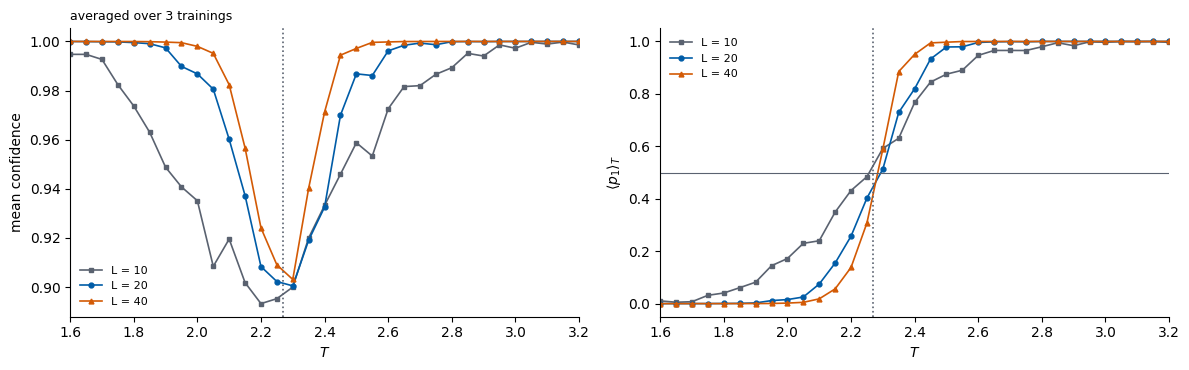

  L   T_c (min confidence), per seed     T_c (<p_1> = 1/2), per seed       mean +- std of the crossing   exact
 10   2.20  2.20  2.25                 2.207  2.245  2.290              2.247 +- 0.041               2.2692
 20   2.20  2.30  2.25                 2.240  2.310  2.304              2.285 +- 0.039               2.2692
 40   2.25  2.25  2.30                 2.282  2.249  2.319              2.283 +- 0.035               2.2692


In [13]:
results = {}                                                 # results[L] = list over training seeds of (T, p_1, T_conf, T_cross)
seeds = (0, 1, 2)
t0 = time.time()
for L_fs in (10, 20, 40):
    cfg, Ts = load_or_generate(L_fs, rng)
    results[L_fs] = []
    for seed in seeds:
        torch.manual_seed(seed)                                  # different random initialisation and batches
        Xa, ya, Xb, yb = make_training_set(cfg, Ts, np.random.default_rng(seed))
        m = IsingCNN(L_fs)
        train(m, Xa, ya, Xb, yb, epochs=3, verbose=False)        # the task is easy: 3 epochs are enough (see Section 4)
        pp = predict(m, cfg)
        _, _, Tc1, Tc2 = estimate_Tc(Ts, pp)
        results[L_fs].append((Ts, pp, Tc1, Tc2))
print(f"{len(seeds)} trainings for each of 3 lattice sizes done in {time.time() - t0:.0f} s")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
styles = {10: (UJGray, "s"), 20: (UJBlue, "o"), 40: (DSOrange, "^")}
for L_fs in sorted(results):
    Ts = results[L_fs][0][0]
    pp = np.concatenate([r[1] for r in results[L_fs]], axis=1)   # pool the seeds
    plot_confidence(ax1, ax2, Ts, pp, f"L = {L_fs}", *styles[L_fs], band=False)
for ax in (ax1, ax2):
    ax.axvline(TC, color=UJGray, ls=":", lw=1.2); ax.set_xlabel("$T$"); ax.set_xlim(1.6, 3.2)
ax2.axhline(0.5, color=UJGray, lw=0.8)
ax1.set_ylabel("mean confidence"); ax2.set_ylabel(r"$\langle p_1\rangle_T$")
ax1.set_title(f"averaged over {len(seeds)} trainings", loc="left", fontsize=9)
ax1.legend(frameon=False, fontsize=8, loc="lower left"); ax2.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); plt.show()

print("  L   T_c (min confidence), per seed     T_c (<p_1> = 1/2), per seed       mean +- std of the crossing   exact")
for L_fs in sorted(results):
    t1 = np.array([r[2] for r in results[L_fs]]); t2 = np.array([r[3] for r in results[L_fs]])
    print(f"{L_fs:3d}   {'  '.join(f'{v:.2f}' for v in t1):30s}   {'  '.join(f'{v:.3f}' for v in t2):30s}   "
          f"{t2.mean():.3f} +- {t2.std(ddof=1):.3f}               {TC:.4f}")

The switch from "ordered" to "disordered" becomes **sharper** as $L$ grows: the transition region of a finite lattice shrinks, as in Lab 010. The estimates themselves depend on $L$, on the temperature grid (spacing $0.05$) and on the random training run. The per-seed values in the table show that the seed-to-seed spread (a standard deviation of about $0.04$ for the crossing) is not small compared with the distance to $T_c$. A single number such as "$\bar T_c$ for $L=50$" is therefore a *pseudo-critical* temperature; extracting $T_c$ itself needs several $L$ and an extrapolation to infinite $L$.
<hr/>
## 7. Inside the network

The network located the transition, but it did not *tell* us anything: no order parameter, no mechanism (Lecture 4, *The Chinese Room*). Three probes look inside it.

### 7.1 Network output and magnetisation
The first hypothesis is the obvious one from physics: the network may simply measure the magnetisation. For every configuration we compute the absolute magnetisation per spin,
$$|m| = \frac1N\Big|\sum_i s_i\Big|, \tag{10}$$
and plot it against the network output $p_1$. If the network had learned "$p_1$ is a function of $|m|$", all points would collapse onto one curve, whatever their temperature.

Spearman rank correlation between |m| and p_1 over all 10200 configurations: -0.914


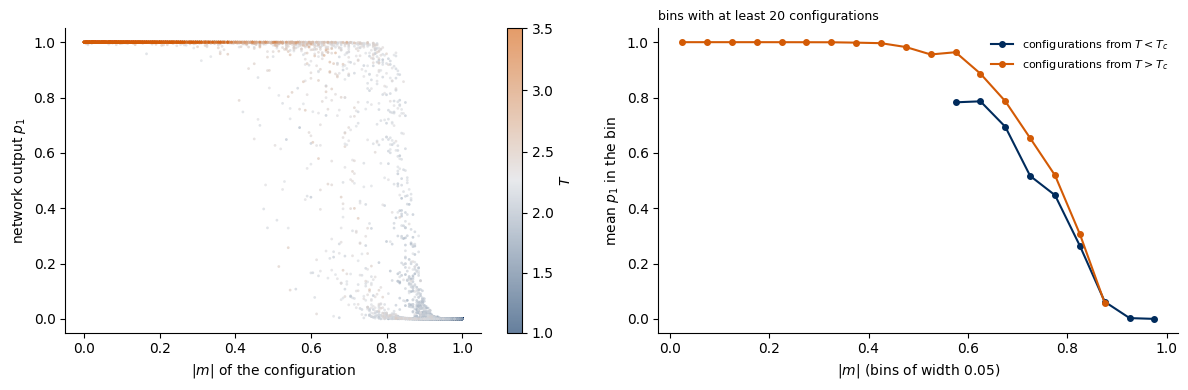

In [14]:
L = 20
absm = np.abs(configs.reshape(*configs.shape[:2], -1).mean(-1).astype(np.float64))     # (temperatures, samples)
TT = np.repeat(temperatures[:, None], configs.shape[1], axis=1)

rho, _ = spearmanr(absm.ravel(), p1.ravel())
print(f"Spearman rank correlation between |m| and p_1 over all {absm.size} configurations: {rho:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
sc = ax1.scatter(absm.ravel(), p1.ravel(), c=TT.ravel(), cmap=cmap_T, norm=TwoSlopeNorm(TC, temperatures.min(), temperatures.max()),
                 s=4, alpha=0.6, lw=0)
plt.colorbar(sc, ax=ax1, label="$T$")
ax1.set_xlabel(r"$|m|$ of the configuration"); ax1.set_ylabel(r"network output $p_1$")

# binned mean of p_1 at fixed |m|, separately for configurations from below and above T_c
bins = np.linspace(0, 1, 21)
centres = 0.5 * (bins[1:] + bins[:-1])
for sel, col, lab in ((TT < TC, UJNavy, r"configurations from $T<T_c$"), (TT > TC, DSOrange, r"configurations from $T>T_c$")):
    idx = np.digitize(absm[sel], bins) - 1
    mean_p = np.array([p1[sel][idx == b].mean() if np.sum(idx == b) >= 20 else np.nan for b in range(len(centres))])
    ax2.plot(centres, mean_p, "o-", color=col, ms=4, label=lab)
ax2.set_xlabel(r"$|m|$ (bins of width 0.05)"); ax2.set_ylabel(r"mean $p_1$ in the bin"); ax2.legend(frameon=False, fontsize=8)
ax2.set_title("bins with at least 20 configurations", loc="left", fontsize=9)
fig.tight_layout(); plt.show()

The Spearman rank correlation printed above measures how well the ordering of configurations by $|m|$ agrees with their ordering by $p_1$ ($\pm1$ for a perfectly monotonic relation, $0$ for unrelated quantities). The right panel asks a sharper question: at the **same** $|m|$, does the network answer differently for configurations from below and above $T_c$? If the two curves lie on top of each other, the output depends (almost) only on $|m|$. If they separate, the network uses more information than the magnetisation.

In the run stored in this notebook the rank correlation is strongly negative ($-0.914$: large $|m|$ goes with "ordered"), so $|m|$ explains most of the output. But in the overlapping range of $|m|$ the two curves do not coincide: at equal magnetisation, configurations from $T>T_c$ get a larger $p_1$. The network uses more than $|m|$.

### 7.2 Shuffled spins
We can test directly whether spatial structure matters. For each configuration we **randomly permute the positions** of its spins. This keeps $m$ *exactly*, but destroys all spatial correlations (domains, clusters, domain walls), so the nearest-neighbour energy changes. A pure "$|m|$-detector" would give identical outputs for original and shuffled configurations.

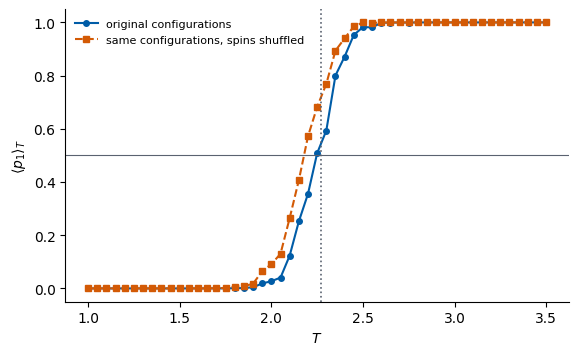

  T     <p_1> original   <p_1> shuffled   <|m|>
1.50      0.000            0.000          0.987
2.00      0.027            0.091          0.915
2.20      0.356            0.572          0.775
2.30      0.594            0.769          0.658
2.40      0.871            0.940          0.488
2.60      0.999            1.000          0.254
3.00      1.000            1.000          0.133


In [15]:
shuffled = configs.reshape(*configs.shape[:2], -1).copy()
for t in range(shuffled.shape[0]):
    for k in range(shuffled.shape[1]):
        rng.shuffle(shuffled[t, k])                                   # random permutation of the sites, same m
shuffled = shuffled.reshape(configs.shape)
p1_shuf = predict(model, shuffled)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(temperatures, p1.mean(1), "o-", color=UJBlue, ms=4, label="original configurations")
ax.plot(temperatures, p1_shuf.mean(1), "s--", color=DSOrange, ms=4, label="same configurations, spins shuffled")
ax.axvline(TC, color=UJGray, ls=":", lw=1.2); ax.axhline(0.5, color=UJGray, lw=0.8)
ax.set_xlabel("$T$"); ax.set_ylabel(r"$\langle p_1\rangle_T$"); ax.legend(frameon=False, fontsize=8)
plt.show()

print("  T     <p_1> original   <p_1> shuffled   <|m|>")
for T in (1.5, 2.0, 2.2, 2.3, 2.4, 2.6, 3.0):
    i = np.argmin(np.abs(temperatures - T))
    print(f"{temperatures[i]:.2f}      {p1[i].mean():.3f}            {p1_shuf[i].mean():.3f}          {absm[i].mean():.3f}")

Where the two curves (and the columns of the printed table) coincide, shuffling did not matter: those configurations are classified by their magnetisation alone. Where they differ, the network's decision depends on the **arrangement** of the spins, not only on how many point up, for example on the size of clusters, which is what changes most near $T_c$.

In the run stored in this notebook, far from $T_c$ shuffling changes nothing, but around $T_c$ the shuffled configurations are called "disordered" more often: at $T=2.20$ the average $p_1$ rises from $0.356$ to $0.572$. Without their large clusters the configurations look more like high-temperature noise to the network, at exactly the same $m$.

### 7.3 The learned filters
The last probe looks at the weights themselves. The first layer applies $32$ different $3\times3$ filters to the spin image. A filter with all weights of the same sign computes a local (smoothed) magnetisation; a filter with weights of both signs responds to local *differences*, i.e. to domain walls, which is what the bond energy $-s_is_j$ measures.

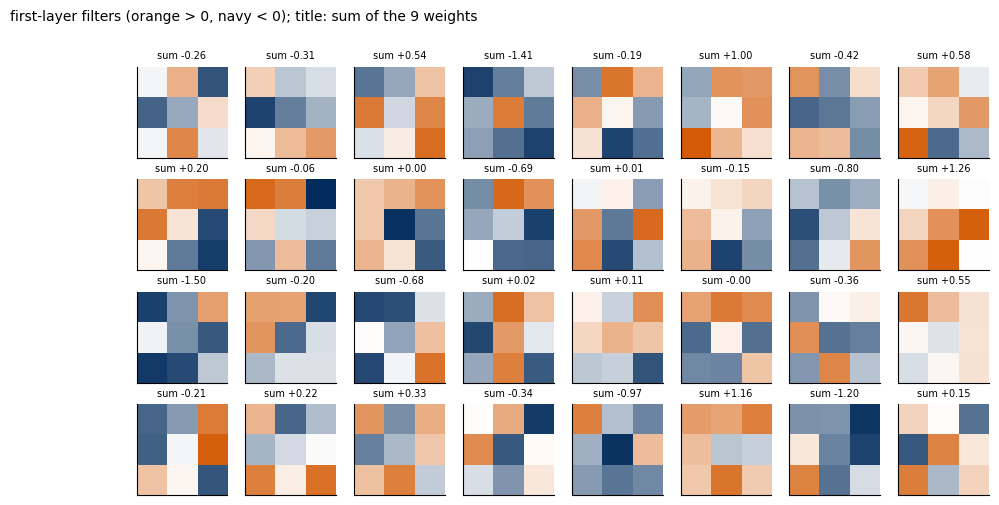

fraction of filters whose 9 weights all have the same sign: 0.00
relative change of the first-layer filters during training, |W - W0| / |W0| = 8.003


In [16]:
W = model.features[0].weight.detach().numpy()[:, 0]                  # (32, 3, 3)
vmax = np.abs(W).max()
fig, axes = plt.subplots(4, 8, figsize=(11, 5.6))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(W[k], cmap=cmap_w, vmin=-vmax, vmax=vmax)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"sum {W[k].sum():+.2f}", fontsize=7)
fig.suptitle("first-layer filters (orange > 0, navy < 0); title: sum of the 9 weights", x=0.01, ha="left", fontsize=10)
plt.show()

same_sign = np.mean([np.all(w > 0) or np.all(w < 0) for w in W])
change = np.linalg.norm(W - W0.numpy()) / np.linalg.norm(W0.numpy())
print(f"fraction of filters whose 9 weights all have the same sign: {same_sign:.2f}")
print(f"relative change of the first-layer filters during training, |W - W0| / |W0| = {change:.3f}")

The printed relative change shows that training moved the filters far from their random initial values, so they are learned, not leftovers. Yet in the run stored here none of them is a plain local average of the spins: each mixes positive and negative weights, i.e. it responds to local spin *patterns*. Whatever the network computes is spread over all the layers (the *systems reply* of Lecture 4). Individual filters are hard to read, and any physical interpretation has to be tested from outside, as in Sections 7.1 and 7.2.

Taken together, the probes give a mixed picture. The network's output is strongly tied to the magnetisation, the order parameter we know from physics, although nobody told it about $m$, and the shuffle test shows that it also uses spatial structure. Finding this out, however, required **us**: we chose $|m|$ as the hypothesis, designed the shuffle test and interpreted the filters. The network itself gave a number, $\bar T_c$, not an explanation. This is the point of the Chinese room, and of the effort to open it (*interpretability*). The exact understanding came from somewhere else: Onsager's solution (Lecture 4 and Lab 012).
<hr/>
## 8. Exercises
1. Move the training windows: $T_{\min}=1.8$, $T_{\max}=2.8$, or asymmetric ones. How does $\bar T_c$ react? When does it become unreliable?
2. Replace the CNN by a fully connected network on the flattened image (as for MNIST). Is it as good? Does the shuffle test give a different answer? (Hint: a fully connected network has no notion of neighbours.)
3. Remove the random global spin flip from the data (Lab 010, Section 5) — i.e. all low-$T$ configurations have $m>0$. Train again and test on flipped configurations $-\boldsymbol s$. What went wrong?
4. Train with **three** classes (low, intermediate, high temperature bins) or regress $T$ directly. What does the network predict near $T_c$?